## Heart_disease_prediction

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns # For creating plots
import matplotlib.ticker as mtick # For specifying the axes tick format 
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
heart_disease_risk = pd.read_csv('heart_disease_risk_prediction.csv')

In [3]:
heart_disease_risk.head()

,Patient_ID,Age,Gender,Height_cm,Weight_kg,BMI,Smoking,Alcohol,Physical_Activity,Stress_Level,...,Max_Heart_Rate,Oxygen_Saturation,Resting_ECG,Exercise_Angina,ST_Depression,Chest_Pain_Type,Daily_Steps,Water_Intake,Medication,Heart_Disease
0,1,69,Male,178.6,51.4,16.1,No,Yes,Moderate,Medium,...,145,99.7,Normal,No,0.8,Asymptomatic,7685,1.6,No,0
1,2,32,Male,170.4,47.2,16.3,No,Yes,Moderate,Medium,...,196,96.8,ST-T Abnormality,No,1.5,Atypical Angina,5485,1.6,No,0
2,3,89,Female,162.4,56.3,21.3,No,Yes,Moderate,Medium,...,125,100.0,Left Ventricular Hypertrophy,Yes,2.4,Atypical Angina,8840,2.1,Yes,1
3,4,78,Male,170.6,75.0,25.8,Yes,Yes,High,High,...,150,96.0,Normal,No,1.6,Asymptomatic,13484,1.5,Yes,0
4,5,38,Male,169.9,78.6,27.2,No,No,High,Medium,...,187,97.0,Normal,No,1.8,Non-anginal Pain,10999,2.0,No,0


In [4]:
heart_disease_risk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 30 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Patient_ID           10000 non-null  int64  
 1   Age                  10000 non-null  int64  
 2   Gender               10000 non-null  object 
 3   Height_cm            10000 non-null  float64
 4   Weight_kg            10000 non-null  float64
 5   BMI                  10000 non-null  float64
 6   Smoking              10000 non-null  object 
 7   Alcohol              10000 non-null  object 
 8   Physical_Activity    10000 non-null  object 
 9   Stress_Level         10000 non-null  object 
 10  Sleep_Hours          10000 non-null  int64  
 11  Family_History       10000 non-null  object 
 12  Diabetes             10000 non-null  object 
 13  Hypertension         10000 non-null  object 
 14  Cholesterol          10000 non-null  int64  
 15  HDL_Cholesterol      10000 non-null  

In [5]:
heart_disease_risk.describe()

,Patient_ID,Age,Height_cm,Weight_kg,BMI,Sleep_Hours,Cholesterol,HDL_Cholesterol,LDL_Cholesterol,Triglycerides,Resting_BP,Max_Heart_Rate,Oxygen_Saturation,ST_Depression,Daily_Steps,Water_Intake,Heart_Disease
count,10000.00000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.0000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,54.018800,168.74309,62.230180,21.747520,6.573200,200.177900,54.756500,115.8653,126.793800,116.725200,165.89230,97.514600,1.355270,7346.016700,2.745490,0.241200
std,2886.89568,21.051422,9.27664,13.938507,4.055886,1.293371,25.929861,11.700013,31.2839,29.077621,12.376324,21.45159,1.444847,0.984552,3333.460531,0.718222,0.427833
min,1.00000,18.000000,145.00000,40.000000,11.900000,4.000000,150.000000,30.000000,50.0000,80.000000,100.000000,122.00000,95.000000,0.000000,1001.000000,1.500000,0.000000
25%,2500.75000,36.000000,161.80000,51.600000,18.700000,6.000000,180.000000,46.000000,93.0000,103.000000,107.000000,148.00000,96.300000,0.600000,5243.750000,2.100000,0.000000
50%,5000.50000,54.000000,168.30000,61.700000,21.600000,7.000000,200.000000,55.000000,115.0000,126.000000,115.000000,166.00000,97.500000,1.200000,7106.000000,2.800000,0.000000
75%,7500.25000,72.000000,175.60000,71.700000,24.600000,7.000000,218.000000,65.000000,137.0000,147.000000,122.000000,184.00000,98.800000,1.800000,8943.250000,3.400000,0.000000
max,10000.00000,90.000000,200.00000,115.100000,38.400000,9.000000,290.000000,74.000000,220.0000,228.000000,158.000000,205.00000,100.000000,4.500000,14997.000000,4.000000,1.000000


In [6]:
heart_disease_risk.columns.values

array(['Patient_ID', 'Age', 'Gender', 'Height_cm', 'Weight_kg', 'BMI',
       'Smoking', 'Alcohol', 'Physical_Activity', 'Stress_Level',
       'Sleep_Hours', 'Family_History', 'Diabetes', 'Hypertension',
       'Cholesterol', 'HDL_Cholesterol', 'LDL_Cholesterol',
       'Triglycerides', 'Resting_BP', 'Fasting_Blood_Sugar',
       'Max_Heart_Rate', 'Oxygen_Saturation', 'Resting_ECG',
       'Exercise_Angina', 'ST_Depression', 'Chest_Pain_Type',
       'Daily_Steps', 'Water_Intake', 'Medication', 'Heart_Disease'],
      dtype=object)

In [7]:
df2 = heart_disease_risk.iloc[:,1:]

In [8]:
df2.head()

,Age,Gender,Height_cm,Weight_kg,BMI,Smoking,Alcohol,Physical_Activity,Stress_Level,Sleep_Hours,...,Max_Heart_Rate,Oxygen_Saturation,Resting_ECG,Exercise_Angina,ST_Depression,Chest_Pain_Type,Daily_Steps,Water_Intake,Medication,Heart_Disease
0,69,Male,178.6,51.4,16.1,No,Yes,Moderate,Medium,6,...,145,99.7,Normal,No,0.8,Asymptomatic,7685,1.6,No,0
1,32,Male,170.4,47.2,16.3,No,Yes,Moderate,Medium,7,...,196,96.8,ST-T Abnormality,No,1.5,Atypical Angina,5485,1.6,No,0
2,89,Female,162.4,56.3,21.3,No,Yes,Moderate,Medium,7,...,125,100.0,Left Ventricular Hypertrophy,Yes,2.4,Atypical Angina,8840,2.1,Yes,1
3,78,Male,170.6,75.0,25.8,Yes,Yes,High,High,5,...,150,96.0,Normal,No,1.6,Asymptomatic,13484,1.5,Yes,0
4,38,Male,169.9,78.6,27.2,No,No,High,Medium,6,...,187,97.0,Normal,No,1.8,Non-anginal Pain,10999,2.0,No,0


In [9]:
#Convertin the predictor variable in a binary numeric variable

df2['Gender'].replace(to_replace='Male', value=1, inplace=True)
df2['Gender'].replace(to_replace='Female',  value=0, inplace=True)

In [10]:
df2['Physical_Activity'].replace(to_replace='High', value=2, inplace=True)
df2['Physical_Activity'].replace(to_replace='Low',  value=0, inplace=True)
df2['Physical_Activity'].replace(to_replace='Moderate',  value=1, inplace=True)

In [11]:
df2['Stress_Level'].replace(to_replace='High',  value=2, inplace=True)
df2['Stress_Level'].replace(to_replace='Moderate',  value=1, inplace=True)
df2['Stress_Level'].replace(to_replace='Low',  value=0, inplace=True)

In [12]:
df2['Fasting_Blood_Sugar'].replace(to_replace='High',  value=1, inplace=True)
df2['Fasting_Blood_Sugar'].replace(to_replace='Normal',  value=0, inplace=True)

In [13]:
df2['Resting_ECG'].replace(to_replace='Left Ventricular Hypertrophy',  value=1, inplace=True)
df2['Resting_ECG'].replace(to_replace='Normal',  value=0, inplace=True)
df2['Resting_ECG'].replace(to_replace='ST-T Abnormality',  value=2, inplace=True)

In [14]:
df2['Chest_Pain_Type'].replace(to_replace='Asymptomatic',  value=0, inplace=True)
df2['Chest_Pain_Type'].replace(to_replace='Atypical Angina',  value=1, inplace=True)
df2['Chest_Pain_Type'].replace(to_replace='Non-anginal Pain',  value=2, inplace=True)
df2['Chest_Pain_Type'].replace(to_replace='Typical Angina',  value=3, inplace=True)

In [15]:
#Let's convert all the categorical variables into dummy variables

df_dummies = pd.get_dummies(df2)
df_dummies.head()

,Age,Gender,Height_cm,Weight_kg,BMI,Physical_Activity,Sleep_Hours,Cholesterol,HDL_Cholesterol,LDL_Cholesterol,...,Family_History_No,Family_History_Yes,Diabetes_No,Diabetes_Yes,Hypertension_No,Hypertension_Yes,Exercise_Angina_No,Exercise_Angina_Yes,Medication_No,Medication_Yes
0,69,1,178.6,51.4,16.1,1,6,165,57,85,...,False,True,True,False,True,False,True,False,True,False
1,32,1,170.4,47.2,16.3,1,7,151,69,51,...,True,False,True,False,False,True,True,False,True,False
2,89,0,162.4,56.3,21.3,1,7,224,50,152,...,True,False,False,True,False,True,False,True,False,True
3,78,1,170.6,75.0,25.8,2,5,224,48,155,...,False,True,False,True,True,False,True,False,False,True
4,38,1,169.9,78.6,27.2,2,6,196,61,110,...,False,True,True,False,True,False,True,False,True,False


<Axes: >

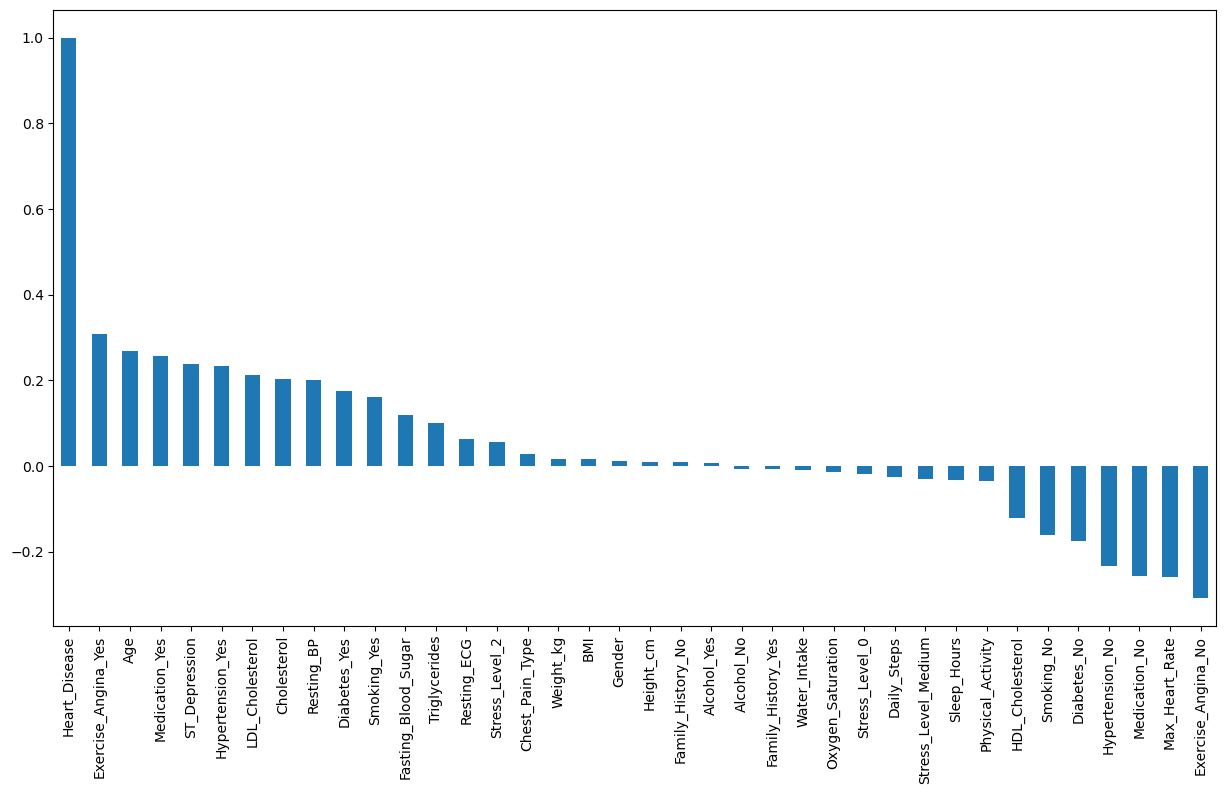

In [16]:
# Get Correlation of "Churn" with other variables

plt.figure(figsize=(15,8))
df_dummies.corr()['Heart_Disease'].sort_values(ascending = False).plot(kind='bar')

In [17]:
## demographic variables like age and gender are highly correlated with heart disease.

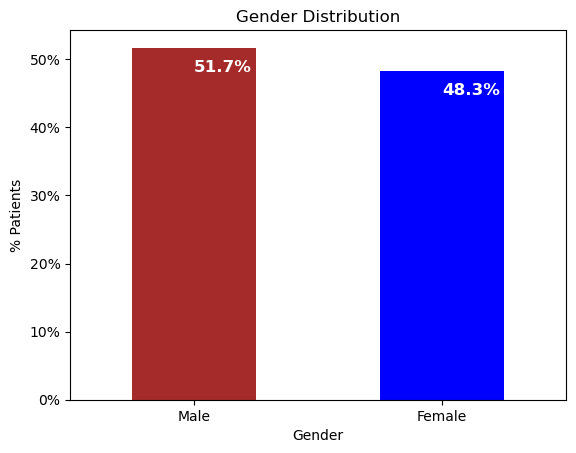

In [18]:
colors = ['brown', 'blue']
gender_counts = heart_disease_risk['Gender'].value_counts()
ax = (gender_counts * 100.0 / len(heart_disease_risk)).plot(
    kind='bar',
    stacked=True,
    rot=0,
    color=colors
)

ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('% Patients')
ax.set_xlabel('Gender')
ax.set_title('Gender Distribution')

# Iterate over the bar heights and add labels to the bars
total = gender_counts.sum()
for bar, count in zip(ax.patches, gender_counts):
    percentage = count / total * 100
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() - 3.5,
            f'{percentage:.1f}%',
            fontsize=12,
            color='white',
            weight='bold'
           )

plt.show()

Text(0.5, 1.0, '% of Smoking')

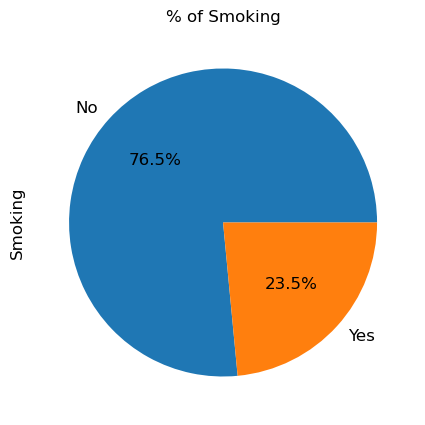

In [19]:
ax = (heart_disease_risk['Smoking'].value_counts()*100.0 /len(heart_disease_risk))\
.plot.pie(autopct='%.1f%%', labels = ['No', 'Yes'],figsize =(5,5), fontsize = 12 )

ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Smoking',fontsize = 12)
ax.set_title('% of Smoking', fontsize = 12)

Text(0.5, 1.0, '% of Alcohol')

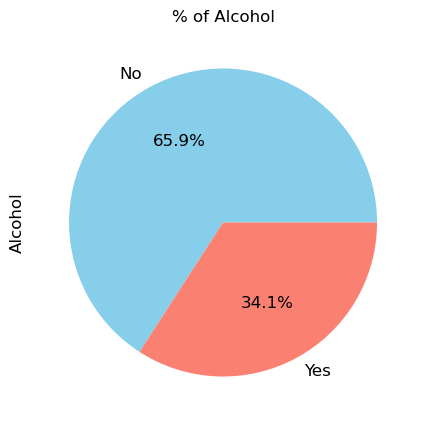

In [20]:
ax = (heart_disease_risk['Alcohol'].value_counts()*100.0 /len(heart_disease_risk))\
.plot.pie(autopct='%.1f%%', labels = ['No', 'Yes'],figsize =(5,5), fontsize = 12 , colors=['skyblue', 'salmon'])

ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Alcohol',fontsize = 12)
ax.set_title('% of Alcohol', fontsize = 12)

Text(0.5, 1.0, '% of Family_History')

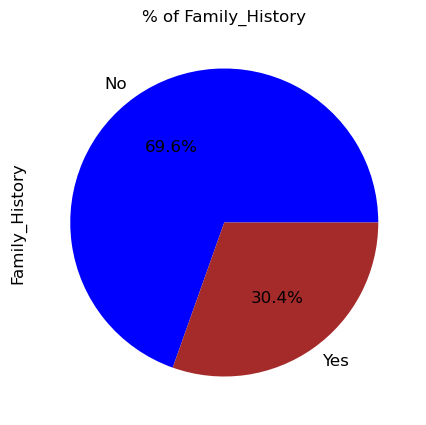

In [21]:
ax = (heart_disease_risk['Family_History'].value_counts()*100.0 /len(heart_disease_risk))\
.plot.pie(autopct='%.1f%%', labels = ['No', 'Yes'],figsize =(5,5), fontsize = 12 , colors=['blue', 'brown'])

ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Family_History',fontsize = 12)
ax.set_title('% of Family_History', fontsize = 12)

Text(0.5, 1.0, '% of Diabetes')

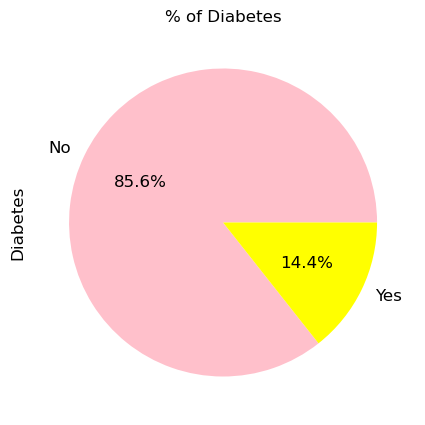

In [22]:
ax = (heart_disease_risk['Diabetes'].value_counts()*100.0 /len(heart_disease_risk))\
.plot.pie(autopct='%.1f%%', labels = ['No', 'Yes'],figsize =(5,5), fontsize = 12 , colors=['pink', 'yellow'])

ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Diabetes',fontsize = 12)
ax.set_title('% of Diabetes', fontsize = 12)

Text(0.5, 1.0, '% of Hypertension')

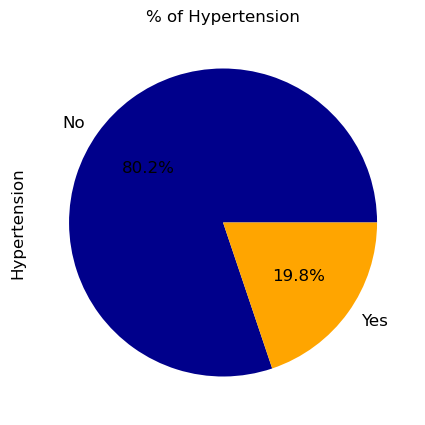

In [23]:
ax = (heart_disease_risk['Hypertension'].value_counts()*100.0 /len(heart_disease_risk))\
.plot.pie(autopct='%.1f%%', labels = ['No', 'Yes'],figsize =(5,5), fontsize = 12 , colors=['darkblue', 'orange'])

ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Hypertension',fontsize = 12)
ax.set_title('% of Hypertension', fontsize = 12)

Text(0.5, 1.0, '% of Fasting_Blood_Sugar')

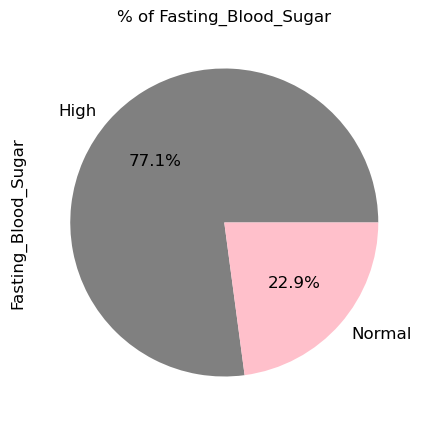

In [24]:
ax = (heart_disease_risk['Fasting_Blood_Sugar'].value_counts()*100.0 /len(heart_disease_risk))\
.plot.pie(autopct='%.1f%%', labels = ['High', 'Normal'],figsize =(5,5), fontsize = 12 , colors=['grey', 'pink'])

ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Fasting_Blood_Sugar',fontsize = 12)
ax.set_title('% of Fasting_Blood_Sugar', fontsize = 12)

Text(0.5, 1.0, '% of Exercise_Angina')

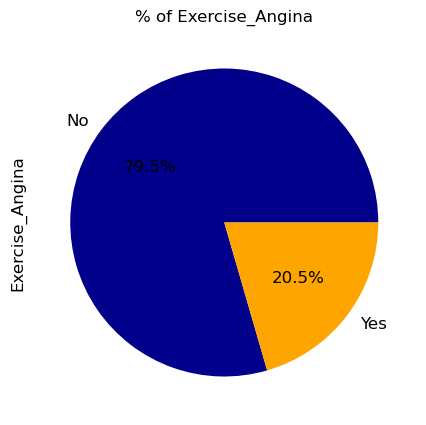

In [25]:
ax = (heart_disease_risk['Exercise_Angina'].value_counts()*100.0 /len(heart_disease_risk))\
.plot.pie(autopct='%.1f%%', labels = ['No', 'Yes'],figsize =(5,5), fontsize = 12 , colors=['darkblue', 'orange'])

ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Exercise_Angina',fontsize = 12)
ax.set_title('% of Exercise_Angina', fontsize = 12)

Text(0.5, 1.0, '% of Medication')

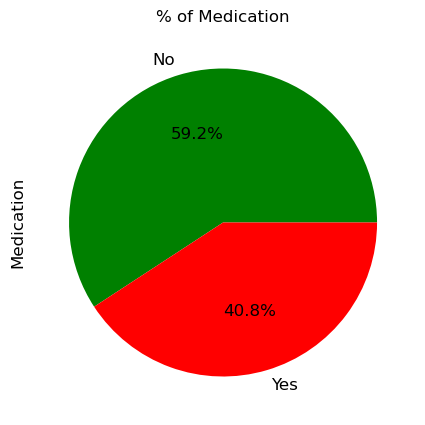

In [26]:
ax = (heart_disease_risk['Medication'].value_counts()*100.0 /len(heart_disease_risk))\
.plot.pie(autopct='%.1f%%', labels = ['No', 'Yes'],figsize =(5,5), fontsize = 12 , colors=['green', 'red'])

ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Medication',fontsize = 12)
ax.set_title('% of Medication', fontsize = 12)

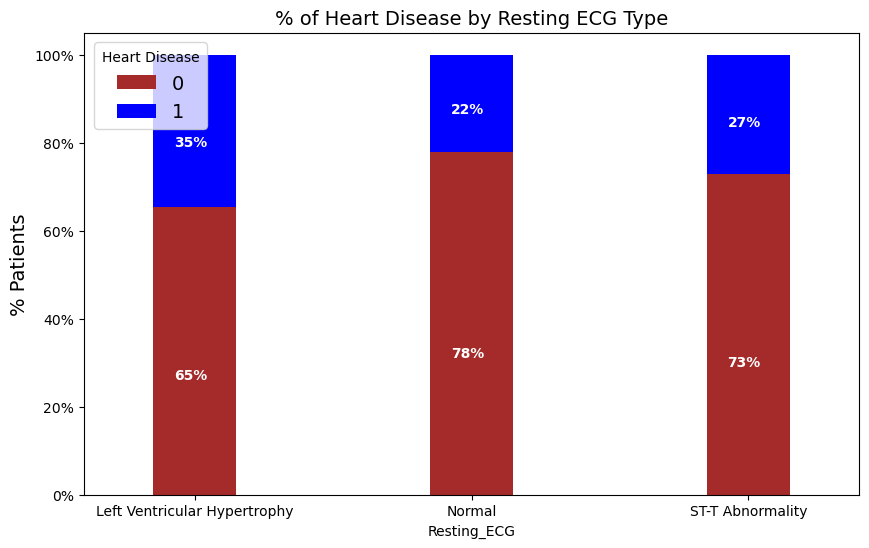

In [27]:
# colors = ['orange','brown']
heart_disease_by_ecg = heart_disease_risk.groupby(['Resting_ECG','Heart_Disease']).size().unstack()

ax = (heart_disease_by_ecg.T*100.0 / heart_disease_by_ecg.T.sum()).T.plot(kind='bar',
                                                                width = 0.3,
                                                                stacked = True,
                                                                rot = 0, 
                                                                figsize = (10,6),
                                                                color = colors)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(loc='best',prop={'size':14},title = 'Heart Disease')
ax.set_ylabel('% Patients',size = 14)
ax.set_title('% of Heart Disease by Resting ECG Type',size = 14)

# Code to add the data labels on the stacked bar chart
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy() 
    ax.annotate('{:.0f}%'.format(height), (p.get_x()+.25*width, p.get_y()+.4*height),
                color = 'white',
               weight = 'bold',
               size = 10)


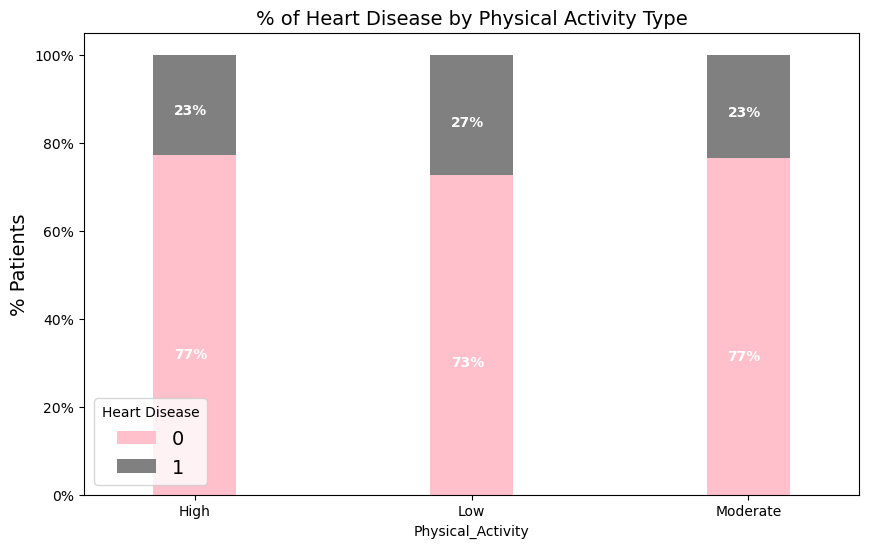

In [28]:
colors = ['pink','grey']
heart_disease_by_physical_activity = heart_disease_risk.groupby(['Physical_Activity','Heart_Disease']).size().unstack()

ax = (heart_disease_by_physical_activity.T*100.0 / heart_disease_by_physical_activity.T.sum()).T.plot(kind='bar',
                                                                width = 0.3,
                                                                stacked = True,
                                                                rot = 0, 
                                                                figsize = (10,6),
                                                                color = colors)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(loc='best',prop={'size':14},title = 'Heart Disease')
ax.set_ylabel('% Patients',size = 14)
ax.set_title('% of Heart Disease by Physical Activity Type',size = 14)

# Code to add the data labels on the stacked bar chart
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy() 
    ax.annotate('{:.0f}%'.format(height), (p.get_x()+.25*width, p.get_y()+.4*height),
                color = 'white',
               weight = 'bold',
               size = 10)


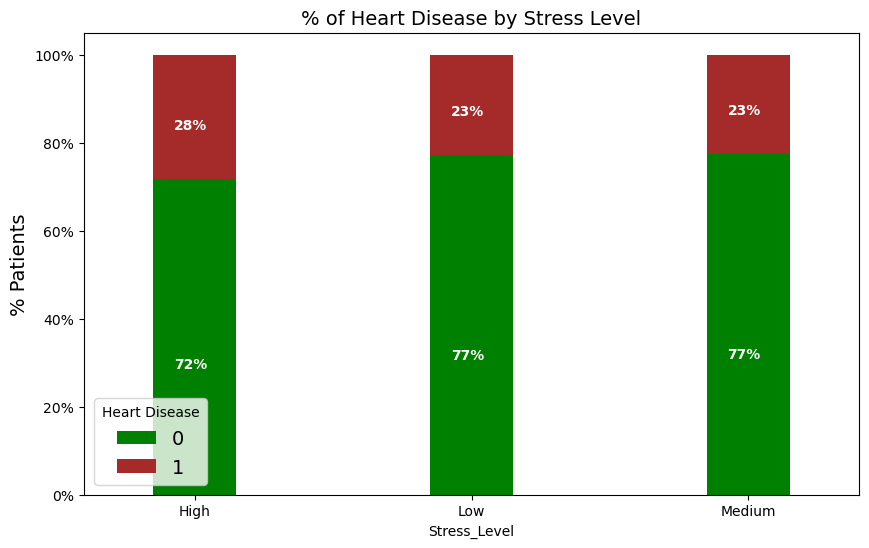

In [29]:
colors = ['green','brown']
heart_disease_by_stress_level = heart_disease_risk.groupby(['Stress_Level','Heart_Disease']).size().unstack()

ax = (heart_disease_by_stress_level.T*100.0 / heart_disease_by_stress_level.T.sum()).T.plot(kind='bar',
                                                                width = 0.3,
                                                                stacked = True,
                                                                rot = 0, 
                                                                figsize = (10,6),
                                                                color = colors)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(loc='best',prop={'size':14},title = 'Heart Disease')
ax.set_ylabel('% Patients',size = 14)
ax.set_title('% of Heart Disease by Stress Level',size = 14)

# Code to add the data labels on the stacked bar chart
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy() 
    ax.annotate('{:.0f}%'.format(height), (p.get_x()+.25*width, p.get_y()+.4*height),
                color = 'white',
               weight = 'bold',
               size = 10)


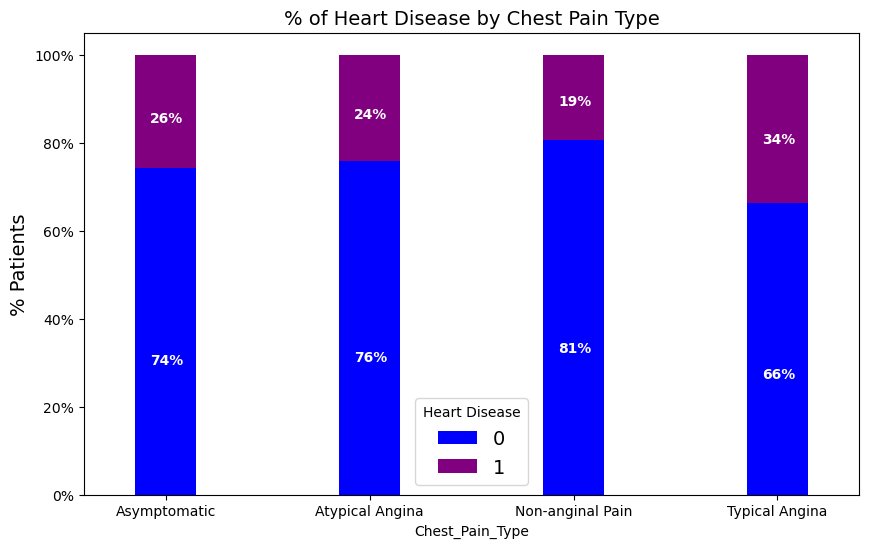

In [30]:
colors = ['blue','purple']
heart_disease_by_chest_pain_type = heart_disease_risk.groupby(['Chest_Pain_Type','Heart_Disease']).size().unstack()

ax = (heart_disease_by_chest_pain_type.T*100.0 / heart_disease_by_chest_pain_type.T.sum()).T.plot(kind='bar',
                                                                width = 0.3,
                                                                stacked = True,
                                                                rot = 0, 
                                                                figsize = (10,6),
                                                                color = colors)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(loc='best',prop={'size':14},title = 'Heart Disease')
ax.set_ylabel('% Patients',size = 14)
ax.set_title('% of Heart Disease by Chest Pain Type',size = 14)

# Code to add the data labels on the stacked bar chart
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy() 
    ax.annotate('{:.0f}%'.format(height), (p.get_x()+.25*width, p.get_y()+.4*height),
                color = 'white',
               weight = 'bold',
               size = 10)


In [31]:
#decision tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split

In [33]:
x_dt=df_dummies.drop(columns=["Heart_Disease"],axis=1)
y_dt=df_dummies["Heart_Disease"]

In [34]:
x_train_dt,x_test_dt,y_train_dt,y_test_dt=train_test_split(x_dt,y_dt,test_size=0.4)


In [35]:
from sklearn.ensemble import RandomForestRegressor
dt=DecisionTreeRegressor(criterion="squared_error",max_depth=6,random_state=42)
rf=RandomForestRegressor(n_estimators=20,random_state=42)

In [36]:
dt

DecisionTreeRegressor(max_depth=6, random_state=42)

In [37]:
dt.fit(x_train_dt,y_train_dt)

DecisionTreeRegressor(max_depth=6, random_state=42)

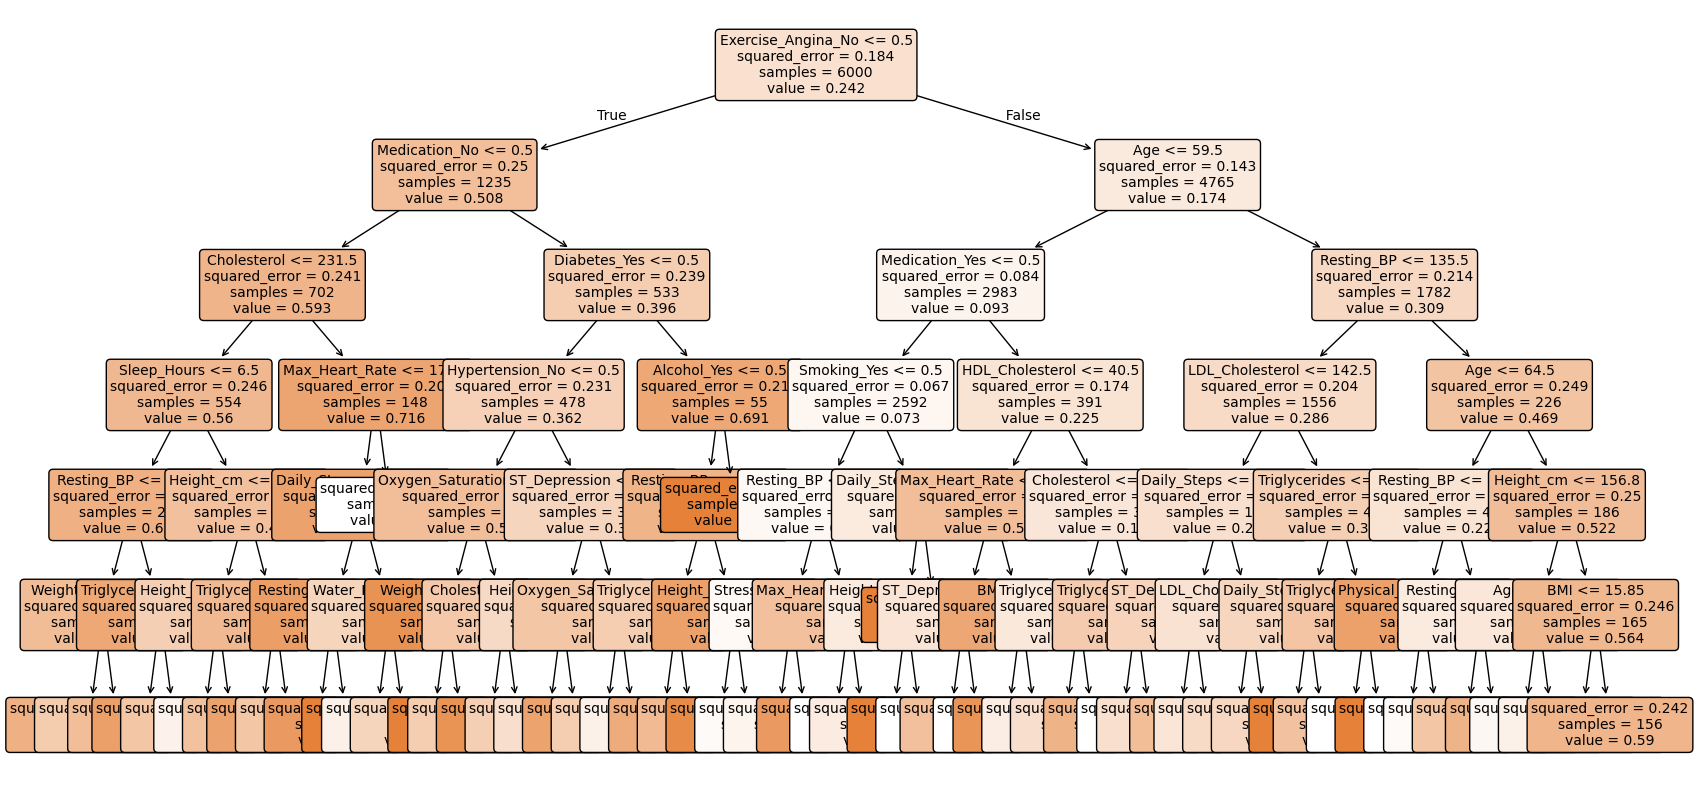

In [38]:
from sklearn import tree
plt.figure(figsize=(20,10))
tree.plot_tree(dt,filled=True,feature_names=x_dt.columns, rounded=True, fontsize=10)
plt.show()

In [38]:
## predective modeling  - ML algorithms

In [ ]:
#Logistic Regression
# We will use the data frame where we had created dummy variables

y = df_dummies['Heart_Disease'].values
X = df_dummies.drop(columns = ['Heart_Disease'])

# Scaling all the variables to a range of 0 to 1

from sklearn.preprocessing import MinMaxScaler

features = X.columns.values
scaler = MinMaxScaler(feature_range = (0,1))
scaler.fit(X)
X = pd.DataFrame(scaler.transform(X))
X.columns = features


In [40]:
# Create Train & Test Data

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [41]:
# Running logistic regression model

from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
result = model.fit(X_train, y_train)

In [42]:
from sklearn import metrics
prediction_test = model.predict(X_test)

# Print the prediction accuracy

print (metrics.accuracy_score(y_test, prediction_test))

0.777


Axes(0.125,0.11;0.775x0.77)


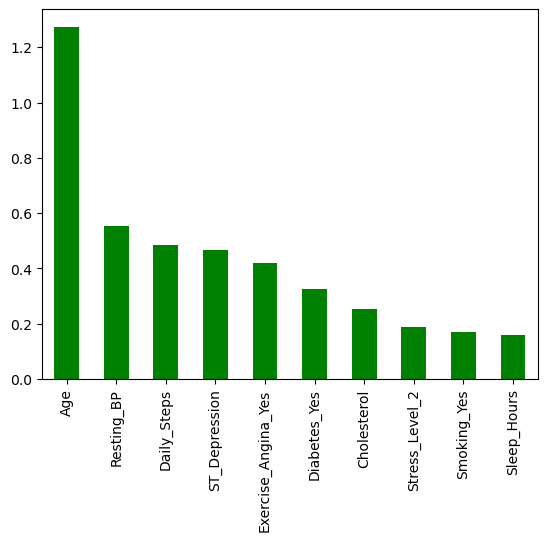

In [43]:
# To get the weights of all the variables

weights = pd.Series(model.coef_[0],
                 index=X.columns.values)
print (weights.sort_values(ascending = False)[:10].plot(kind='bar', color = 'green'))

Axes(0.125,0.11;0.775x0.77)


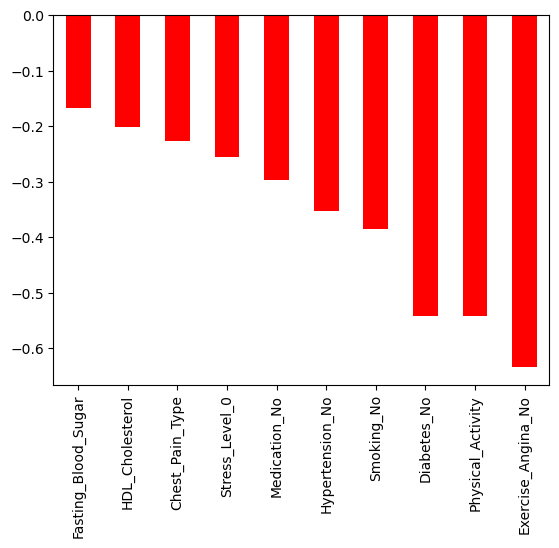

In [44]:
print(weights.sort_values(ascending = False)[-10:].plot(kind='bar', color = 'red'))

In [45]:
## random forest classifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)
model_rf = RandomForestClassifier(n_estimators=1000, oob_score=True, n_jobs=-1, random_state=50, max_leaf_nodes=30)
model_rf.fit(X_train, y_train)

# Make predictions

prediction_test = model_rf.predict(X_test)
print(metrics.accuracy_score(y_test, prediction_test))

0.7755


<Axes: >

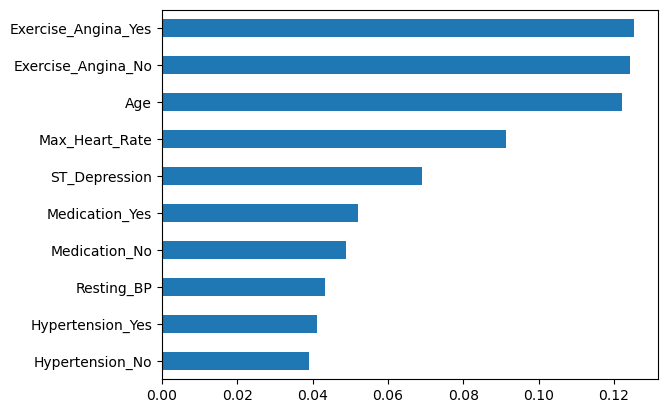

In [46]:
importances = model_rf.feature_importances_
weights = pd.Series(importances,
                 index=X.columns.values)
weights.sort_values()[-10:].plot(kind = 'barh')

In [48]:
## support vector machine
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [49]:
from sklearn.svm import SVC

model.svm = SVC(kernel='linear') 
model.svm.fit(X_train,y_train)
preds = model.svm.predict(X_test)
metrics.accuracy_score(y_test, preds)

0.742

In [50]:
# Create the Confusion matrix
from sklearn.metrics import classification_report, confusion_matrix  
print(confusion_matrix(y_test,preds))

[[1484    0]
 [ 516    0]]


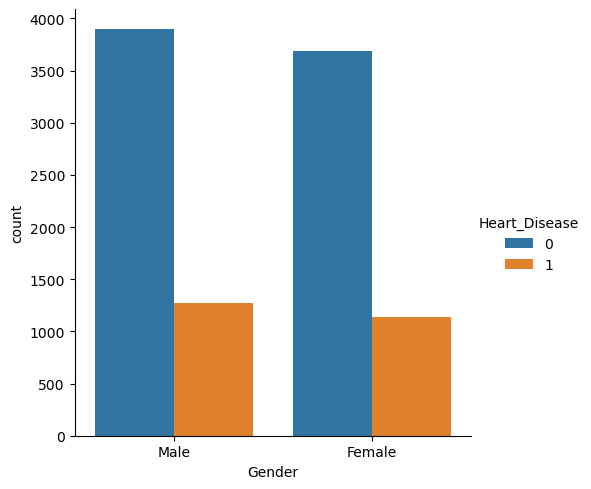

In [51]:
ax1 = sns.catplot(x="Gender", kind="count", hue="Heart_Disease", data=heart_disease_risk,
                  estimator=lambda x: sum(x==0)*100.0/len(x))

In [54]:
## ADA Boost
from sklearn.ensemble import AdaBoostClassifier
model = AdaBoostClassifier()
# n_estimators = 50 (default value) 
# base_estimator = DecisionTreeClassifier (default value)
model.fit(X_train,y_train)
preds = model.predict(X_test)
metrics.accuracy_score(y_test, preds)

0.7735

In [55]:
# xg boost
from xgboost import XGBClassifier
model = XGBClassifier()
model.fit(X_train, y_train)
preds = model.predict(X_test)
metrics.accuracy_score(y_test, preds)

0.7545